# Credit Risk Model: Predicting Loan Defaults

When a bank approves a loan, it is making a judgement about whether that person will pay it back. In this project, I wanted to see how well that judgement can be made from data, and how a bank might turn a model's prediction into a sensible lending decision.

I used the German Credit dataset, which is publicly available on OpenML ("credit-g"). It contains 1,000 past loan applicants, with 20 details about each one, such as their checking account balance, loan amount, loan purpose, savings and employment. Each applicant is labelled as either a good or bad credit risk.

## My approach

I started by exploring the data with SQL to see which groups of applicants defaulted most often. I then built two models: a logistic regression, which is the traditional and easily explained choice for credit scoring, and an XGBoost model, to see whether a machine learning approach could do better.

I tested both models on applicants they had not seen during training. I then used the costs of wrong decisions to choose a sensible approval cut-off. Finally, I checked whether the model treated younger and older applicants fairly.

In [1]:
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.compose import ColumnTransformer
from sklearn.datasets import fetch_openml
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42

## 1. Loading the data

I loaded the dataset directly from OpenML. The original label is "good" or "bad", so I converted it into a simple 0/1 column called `defaulted`, where 1 means the applicant defaulted.

In [2]:
df = fetch_openml("credit-g", version=1, as_frame=True).frame
df["defaulted"] = (df["class"] == "bad").astype(int)
df = df.drop(columns="class")

print(df.shape)
print(f"Overall default rate: {df['defaulted'].mean():.1%}")
df.head()

(1000, 21)
Overall default rate: 30.0%


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,defaulted
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,0
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,1
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,0
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,0
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,1


## 2. Exploring the data with SQL

Before building any models, I wanted to understand which applicants were most likely to default. I loaded the data into a SQLite database and wrote SQL queries to compare default rates across checking account status, loan purpose and loan length.

In [3]:
conn = sqlite3.connect(":memory:")
df_sql = df.copy()
for col in df_sql.select_dtypes("category").columns:
    df_sql[col] = df_sql[col].astype(str)
df_sql.to_sql("loans", conn, index=False)

def q(sql):
    return pd.read_sql(sql, conn)


print(q("""
SELECT checking_status,
       COUNT(*)                       AS applicants,
       ROUND(AVG(defaulted) * 100, 1) AS default_rate_pct
FROM loans
GROUP BY checking_status
ORDER BY default_rate_pct DESC;
"""))


print(q("""
SELECT purpose,
       COUNT(*)                       AS applicants,
       ROUND(AVG(credit_amount), 0)   AS avg_amount,
       ROUND(AVG(defaulted) * 100, 1) AS default_rate_pct
FROM loans
GROUP BY purpose
HAVING COUNT(*) >= 30
ORDER BY default_rate_pct DESC;
"""))

# Default rate by loan length
print(q("""
SELECT CASE WHEN duration <= 12 THEN '1: up to 12 months'
            WHEN duration <= 24 THEN '2: 13-24 months'
            ELSE '3: over 24 months' END AS loan_length,
       COUNT(*)                       AS applicants,
       ROUND(AVG(defaulted) * 100, 1) AS default_rate_pct
FROM loans
GROUP BY loan_length
ORDER BY loan_length;
"""))

  checking_status  applicants  default_rate_pct
0              <0         274              49.3
1        0<=X<200         269              39.0
2           >=200          63              22.2
3     no checking         394              11.7
               purpose  applicants  avg_amount  default_rate_pct
0            education          50      3180.0              44.0
1              new car         234      3063.0              38.0
2             business          97      4158.0              35.1
3  furniture/equipment         181      3067.0              32.0
4             radio/tv         280      2488.0              22.1
5             used car         103      5370.0              16.5
          loan_length  applicants  default_rate_pct
0  1: up to 12 months         359              21.2
1     2: 13-24 months         411              29.7
2   3: over 24 months         230              44.3


**What I found:**

Overall, 30% of applicants defaulted, but this varied a lot between groups.

Checking account status stood out the most. Almost half (49%) of applicants with a negative balance defaulted, compared with just 12% of those without a checking account.

Loan purpose also mattered. Education loans (44%) and new car loans (38%) were the riskiest, while used car loans were the safest at 17%, even though they were the largest loans on average.

Longer loans were noticeably riskier. Default rates rose from 21% for loans of up to a year to 44% for loans lasting more than two years.

## 3. Preparing the data for modelling

Before training any models, I removed two columns: `personal_status`, which combines a person's sex and marital status, and `foreign_worker`. A bank shouldn't base lending decisions on either of these, so I didn't want the models to learn from them. I kept age in for now, but I check later whether the model treats younger applicants fairly.

I then split the data into two parts. The models learn from 75% of applicants (the training set), and I keep the other 25% aside (the test set) to check how well they predict for people they've never seen.

In [4]:
X = df.drop(columns=["defaulted", "personal_status", "foreign_worker"])
y = df["defaulted"]

num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = X.select_dtypes("category").columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {len(X_train)} | Test: {len(X_test)}")

Train: 750 | Test: 250


## 4. Model 1: Logistic regression

I started with logistic regression because it is the traditional model for credit scoring. Its big advantage is that it is easy to explain: for every feature, it tells you whether it pushes an applicant's risk up or down, and by how much.

To make the results easy to read, I converted the model's coefficients into odds ratios. An odds ratio above 1 means a feature increases the risk of default, and below 1 means it reduces it.

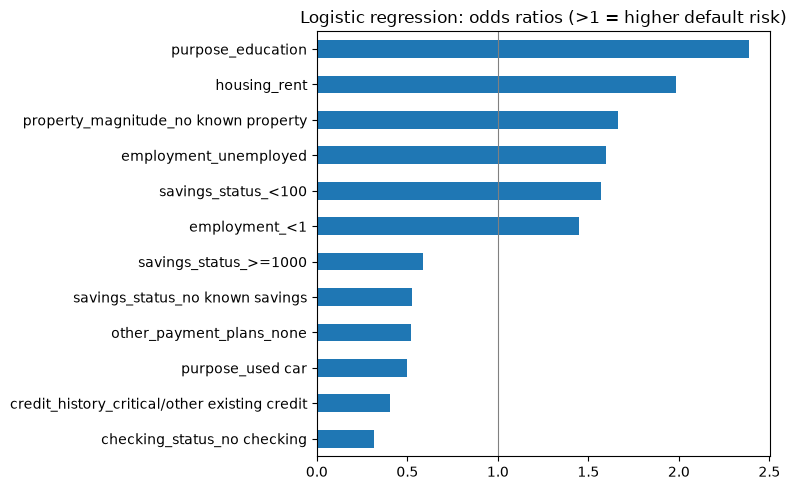

In [5]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), cat_cols),
])
logreg = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000, C=0.5)),
])
logreg.fit(X_train, y_train)
p_logreg = logreg.predict_proba(X_test)[:, 1]


names = [n.split("__", 1)[1] for n in logreg.named_steps["prep"].get_feature_names_out()]
coefs = pd.Series(logreg.named_steps["model"].coef_[0], index=names)
odds = np.exp(coefs).sort_values()
top = pd.concat([odds.head(6), odds.tail(6)])
top.plot(kind="barh", figsize=(8, 5))
plt.axvline(1, color="grey", linewidth=0.8)
plt.title("Logistic regression: odds ratios (>1 = higher default risk)")
plt.tight_layout()
plt.savefig("odds_ratios.png", dpi=150)
plt.show()

**What the model shows:**

The biggest warning signs were loans for education (2.4 times the odds of default), renting a home (2.0 times) and having no property (1.7 times). Being unemployed and having low savings also increased the risk, as did longer and larger loans.

On the other side, applicants without a checking account were much less likely to default (0.31 times the odds compared with those holding a small positive balance), and used car loans were also lower risk.

One result surprised me. Applicants with a "critical" credit history came out as *lower* risk. I think this is because the data only includes people the bank actually approved, so anyone approved despite a poor history was probably strong in other ways. It's a good reminder that a model can only learn from the data it's given, and a real bank would investigate a result like this before relying on it.

## 5. Model 2: XGBoost

Next, I wanted to see whether a machine learning model could predict defaults more accurately. XGBoost builds hundreds of small decision trees, where each new tree learns from the mistakes of the ones before it. This lets it pick up patterns that logistic regression can miss, such as combinations of features that only matter together.

The trade-off is that XGBoost is much harder to explain than logistic regression, which matters in lending. I compare both models in the next section.

In [6]:
booster = xgb.XGBClassifier(
    n_estimators=300, learning_rate=0.05, max_depth=3,
    subsample=0.8, colsample_bytree=0.8,
    enable_categorical=True, tree_method="hist",
    random_state=RANDOM_STATE, eval_metric="auc",
)
booster.fit(X_train, y_train)
p_xgb = booster.predict_proba(X_test)[:, 1]

## 6. Comparing the models

To judge the models fairly, I tested them on the 250 applicants they hadn't seen during training.

I used **AUC** to measure how well each model separates people who default from people who repay. It's the chance that the model gives a randomly chosen defaulter a higher risk score than a randomly chosen good customer. 0.5 is no better than guessing and 1 is perfect. Banks often report the same thing as a **Gini** score, which is calculated as 2 × AUC − 1.

              Model   AUC  Gini
Logistic regression 0.803 0.607
            XGBoost 0.823 0.646


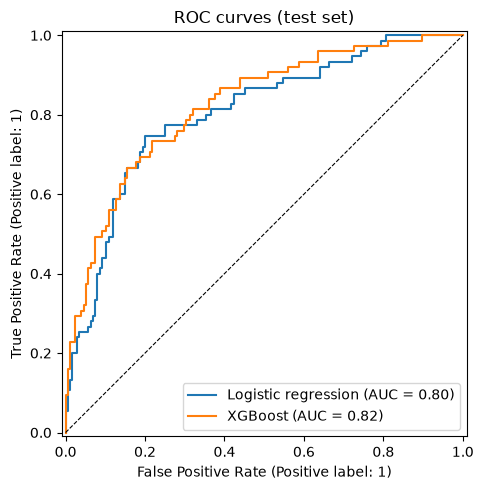

In [7]:
results = pd.DataFrame({
    "Model": ["Logistic regression", "XGBoost"],
    "AUC": [roc_auc_score(y_test, p_logreg), roc_auc_score(y_test, p_xgb)],
})
results["Gini"] = 2 * results["AUC"] - 1
print(results.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 5))
RocCurveDisplay.from_predictions(y_test, p_logreg, name="Logistic regression", ax=ax)
RocCurveDisplay.from_predictions(y_test, p_xgb, name="XGBoost", ax=ax)
ax.plot([0, 1], [0, 1], "k--", linewidth=0.8)
ax.set_title("ROC curves (test set)")
plt.tight_layout()
plt.savefig("roc_curves.png", dpi=150)
plt.show()

**Result:**

Both models performed well. XGBoost scored slightly higher (AUC 0.818, Gini 0.64) than logistic regression (AUC 0.803, Gini 0.61).

However, with only 250 people in the test set, a difference this small could easily be down to chance. More importantly, lenders need to be able to explain why someone was refused a loan, both to regulators and to the customer. Logistic regression gives clear reasons for every decision, so I chose it as the model to base lending decisions on.

### Choosing when to approve a loan

A model gives each applicant a probability of defaulting, but the bank still has to decide where to draw the line. By default, people often use 0.5: reject anyone with more than a 50% chance of defaulting.

But the two kinds of mistake don't cost the same. This dataset comes with a cost guide: approving someone who then defaults costs **5 times** as much as turning away someone who would have repaid. So I tested every cut-off from 0.05 to 0.95 and chose the one with the lowest total cost.

Cost at 0.5 threshold: 186
Best threshold: 0.30, cost 130
Approval rate at best threshold: 58.8%


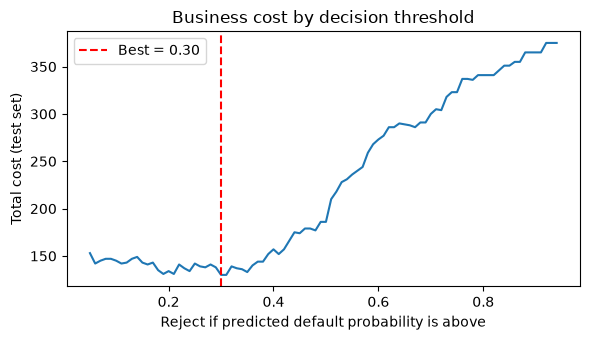

In [8]:
def total_cost(y_true, prob, threshold, cost_fn=5, cost_fp=1):
    reject = prob >= threshold
    missed_defaults = ((~reject) & (y_true == 1)).sum() 
    lost_good = (reject & (y_true == 0)).sum()            
    return cost_fn * missed_defaults + cost_fp * lost_good

best_model_probs = p_logreg  
thresholds = np.arange(0.05, 0.95, 0.01)
costs = [total_cost(y_test.to_numpy(), best_model_probs, t) for t in thresholds]
best_t = thresholds[int(np.argmin(costs))]

print(f"Cost at 0.5 threshold: {total_cost(y_test.to_numpy(), best_model_probs, 0.5)}")
print(f"Best threshold: {best_t:.2f}, cost {min(costs)}")
print(f"Approval rate at best threshold: {(best_model_probs < best_t).mean():.1%}")

plt.figure(figsize=(6, 3.5))
plt.plot(thresholds, costs)
plt.axvline(best_t, color="red", linestyle="--", label=f"Best = {best_t:.2f}")
plt.xlabel("Reject if predicted default probability is above")
plt.ylabel("Total cost (test set)")
plt.title("Business cost by decision threshold")
plt.legend()
plt.tight_layout()
plt.savefig("cost_threshold.png", dpi=150)
plt.show()

**Result:**

The total cost was lowest when the bank rejects anyone with a predicted default probability above **0.30**, rather than the usual 0.50. This brought the cost down from 186 to 130 on the test set, a **30% reduction**, while still approving around 59% of applicants.

This makes sense: because a missed default is so much more expensive than a lost customer, it pays for the bank to be more cautious. The chart also shows that costs rise sharply once the threshold goes above about 0.4.

## 7. Checking for fairness

A model can be accurate overall and still treat some groups of people unfairly. Since I kept age in the model, I wanted to check how it treats younger applicants.

Using the 0.30 threshold, I compared two groups, under-25s and everyone else, on two things: how often the model would approve them, and how often they actually defaulted. If one group were approved much less often without actually being riskier, that would be a warning sign.

In [9]:
fair = pd.DataFrame({
    "age_group": np.where(X_test["age"] < 25, "Under 25", "25 and over"),
    "approved": best_model_probs < best_t,
    "defaulted": y_test.to_numpy(),
})
summary = fair.groupby("age_group").agg(
    applicants=("approved", "size"),
    approval_rate=("approved", "mean"),
    actual_default_rate=("defaulted", "mean"),
)
print(summary.round(3))

             applicants  approval_rate  actual_default_rate
age_group                                                  
25 and over         202          0.619                0.248
Under 25             48          0.458                0.521


**Result:**

Under-25s were approved less often than older applicants (46% compared with 62%). At first this looks like it could be unfair, but their actual default rate was also much higher: 52% of under-25s in the test set defaulted, compared with 25% of older applicants. So the gap in approvals reflects a real difference in repayment, rather than the model being biased against younger people.

That said, I'd be cautious about reading too much into this. There are only 48 under-25s in the test set, and age may be standing in for other things, such as shorter time in employment or not owning property. In practice, a bank would keep monitoring this and check that age alone isn't the reason people are being turned down.


## 8. Conclusions

Both models were good at telling apart applicants who would default from those who would repay. XGBoost scored slightly higher (AUC 0.818 compared with 0.803), but the gap was small for a test set of 250 people. Because lenders need to explain their decisions, I think logistic regression is the better choice here.

The strongest warning signs of default were a person's checking account status, the purpose of the loan (especially education and new cars), longer and larger loans, renting and having no property.

Choosing the approval cut-off based on the real cost of mistakes, rather than the usual 0.5, made the biggest practical difference: it reduced the cost of wrong decisions by 30%.

The fairness check showed that younger applicants were approved less often, but this matched their higher default rate. Because the group was small, it's something that would need ongoing monitoring.

## Limitations

- The dataset only has 1,000 applicants, so results from a 250-person test set can vary by chance.
- The data comes from Germany in the 1990s, so it may not reflect UK borrowers today.
- The data only includes people the bank approved. The model can't learn anything about the people who were turned down, which can lead to strange results like the "critical" credit history finding.
- The 5-to-1 cost ratio is the dataset's standard guide, not a real bank's figures.

## What I would do next

- Use cross-validation to get more reliable results from a small dataset
- Use SHAP values to explain individual decisions made by the XGBoost model
- Try the same approach on a larger, more recent dataset